# DATA ANALYSIS SAMPLE PROJECT 1.

## Car Price Dataset example

### Dataset description

#### Why dataset description?
Dataset description is neccesary for understanding the datset before analysis as analyst you do not have too rush into data analysis without first understanding you scope and other more metadata on variables you are going to carry out analysis from.

This essential for data analysis to go smoothly after understandng the purpose structure and more basic information required on dataset.

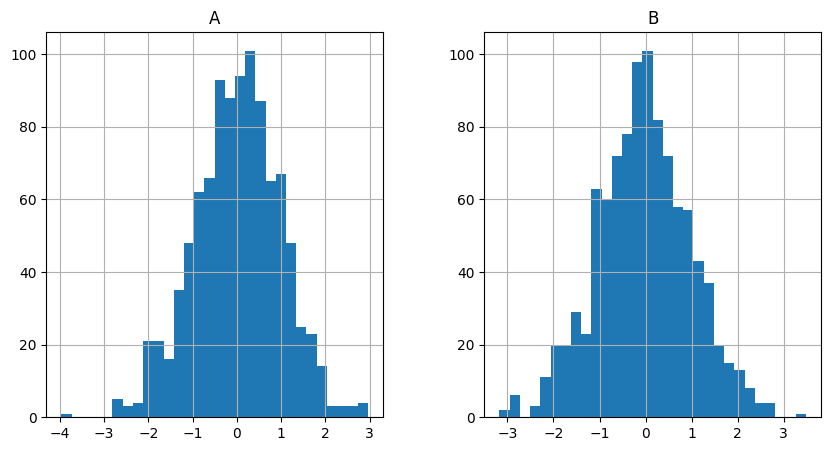

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#pip install jupyterlab notebook pandas numpy matplotlib seaborn scikit-learn plotly streamlit pipreqs

#pipreqs --force --ignore .venv,venv,__pycache__,.ipynb_checkpoints .
#pip install -r requirements.txt
#pip install --upgrade pip
#pip install pandas==1.5.3 numpy==1.24.3 matplotlib==3.7.1 seaborn==0.12.2 scikit-learn==1.2.2 plotly==5.14.1 streamlit==1.20.0
#python -m streamlit run your_script.py
# This script sets up a Python environment for data analysis and visualization.
# It imports essential libraries such as pandas, numpy, matplotlib, and seaborn.
# You can extend this script by adding your data analysis and visualization code below.
# Example: Create a simple DataFrame and plot a histogram
data = pd.DataFrame({
    'A': np.random.randn(1000),
    'B': np.random.randn(1000)
})
data.hist(bins=30, figsize=(10, 5))
plt.show()

In [ ]:
df=pd.read_csv("D:/USER/NISR_trainings/NISR_trainings/DATA_DATA/car price data.csv")
df.head()

In [ ]:
df.columns
df.info()

In [ ]:
#df.describe()
df.dtypes


In [ ]:
#df.isnull().sum()
data=df[['Year','Selling_Price','Present_Price','Kms_Driven','Owner','Car_Name']]

In [ ]:
df["Year"].unique()
df["Selling_Price"].unique()
df["Present_Price"].unique()

In [ ]:
df['Selling_Price'].hist(bins=50)

In [ ]:
df['Selling_Price']

In [ ]:
df[['Selling_Price','Present_Price']]

In [ ]:
df.loc[:, "Selling_Price"]

In [ ]:
data.head() #this shows only sliced columns which are integers

In [ ]:
df.loc[:,["Year","Selling_Price","Present_Price","Kms_Driven","Owner","Car_Name"]]

In [ ]:
data.info()

In [ ]:
data.min()   

In [ ]:
data.iloc[0:10, 0:3]  #This will bring the variable names from the 5th column to the last column for the first 10 rows
#data.iloc[0:10, 5] #This will not bring the variable names because only one column is selected

In [ ]:
df.loc[1:20,"Car_Name":"Seller_Type"]

In [ ]:
# Cross-tab helper: prints counts and row-percentages, shows heatmap and stacked bar
def crosstab_summary(df, row, col, top_n_car_names=None):
    df2 = df.copy()
    if top_n_car_names and row == 'Car_Name':
        top = df2['Car_Name'].value_counts().nlargest(top_n_car_names).index
        df2 = df2[df2['Car_Name'].isin(top)]
    ct = pd.crosstab(df2[row], df2[col])
    ct_pct = ct.div(ct.sum(axis=1), axis=0).multiply(100).round(2)  # row-wise %
    
    print(f"Counts: {row} vs {col}\n")
    display(ct)
    print(f"\nRow-wise percentages (% of each {row} across {col}):\n")
    display(ct_pct)
    
    plt.figure(figsize=(8, 5))
    sns.heatmap(ct, annot=True, fmt='d', cmap='Blues')
    plt.title(f"Heatmap of {row} vs {col} (counts)")
    plt.ylabel(row); plt.xlabel(col)
    plt.tight_layout()
    plt.show()
    
    ct_pct.plot(kind='bar', stacked=True, figsize=(8, 5), colormap='tab20')
    plt.title(f"Stacked bar of {row} vs {col} (row %)")
    plt.ylabel('Percentage')
    plt.legend(title=col, bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()



In [ ]:
crosstab_summary(df, 'Fuel_Type', 'Seller_Type')


In [ ]:
crosstab_summary(df, 'Transmission', 'Fuel_Type')
crosstab_summary(df, 'Owner', 'Fuel_Type')
# For Car_Name (many levels), show top 10 most common names
crosstab_summary(df, 'Car_Name', 'Fuel_Type', top_n_car_names=10)

In [ ]:
data.head(10)
pd.crosstab(df['Fuel_Type'], df['Seller_Type'])

In [ ]:
pd.crosstab(df['Car_Name'],df['Transmission'])
#df.loc[:,['Car_Name']].unique()

In [ ]:
# We are going to make a cross tabulation between two categorical variables
def tabulate(df, var1, var2):
    table = pd.crosstab(df[var1], df[var2])
    return table    
tabulate(df, 'Fuel_Type', 'Seller_Type')

In [ ]:
df.iloc[[3,6,7,8],[0,4,6]] #This will bring the variable names for the selected rows and columns

## FILTERING

In [ ]:
df['Fuel_Type'].unique()

In [ ]:
df_petrol=df.loc[df['Fuel_Type']=='Petrol',:]
df_petrol

In [ ]:
df_petrol_diesel=df.loc[(df['Fuel_Type']=='Petrol') | (df['Fuel_Type']=='Diesel')]
df_petrol_diesel.head(10)

In [ ]:
print(df_petrol_diesel['Fuel_Type'].unique())
print(df_petrol_diesel.shape)

In [ ]:
#Filter cars that has fuel type diesel and selling price less than 7.25
df_diesel_selling_price=df.loc[(df['Fuel_Type']=='Diesel') & (df['Selling_Price']<7.25)]
df_diesel_selling_price
df_diesel_selling_price.shape





















In [ ]:
df['Seller_Type'].unique()

In [ ]:
df['Transmission'].unique()

In [ ]:
#FIlter cars that has fuel type diesel , selling price less than 7.25 and present price greater than 10.5
df_diesel_selling_price=df.loc[(df['Fuel_Type']=='Diesel') & (df['Selling_Price']<7.25) & (df['Present_Price']>10.5)]
df_diesel_selling_price

In [ ]:
#FIlter cars that has fuel type diesel , are Automatic and Selleer type is an individual 
df_diesel_automatic_individual=df.loc[(df['Fuel_Type']=='Diesel') & (df['Transmission']=='Automatic') & (df['Seller_Type']=='Individual')]
df_diesel_automatic_individual.shape

In [ ]:
#print(f"The only {df.loc[(df["Car_Type"]=='Diesel'} which uses {df['Fuel_Type']=='Diesel'} Diesel and are automatic selled also on individuals are{df_diesel_automatic_individual.shape[0]}")

In [ ]:
df.count()

In [ ]:
df['Fuel_Type'].count()

In [ ]:
df.describe().T #This will transpose the output

In [ ]:
df.isnull()
df.isnull().sum()

In [ ]:
df.isna().sum()

In [ ]:
#Filter cars that has fuel type petrol and selling price greater than 5 and are manuals


In [ ]:
df['Age']=2025-df['Year'] #This will add new column of age in dataset
df.columns

In [ ]:
df.head(5)

## TABLES

In [ ]:
pd.crosstab(df['Fuel_Type'], df['Seller_Type'])


In [ ]:
pd.crosstab(index=df['Transmission'], columns=df['Fuel_Type'])


In [ ]:
pd.crosstab(df['Owner'], df['Fuel_Type'])

In [ ]:
pd.crosstab(index=[df['Seller_Type'], df['Transmission']], columns=df['Fuel_Type'])

In [ ]:
total_percentage=pd.crosstab(index=df['Fuel_Type'], 
                             columns=df['Transmission'], 
                             margins=True, normalize='index',
                             margins_name='Total Percentage')
total_percentage #This will be by row percentages

In [ ]:
#By column
total_percentage=pd.crosstab(index=df['Fuel_Type'], 
                             columns=df['Transmission'], 
                             margins=True, normalize='columns',
                             margins_name='Total Percentage')
total_percentage #This will be by column percentages

In [ ]:
#By row and columns percentages
total_percentage=pd.crosstab(index=df['Fuel_Type'], 
                             columns=df['Transmission'], 
                             margins=True, 
                             normalize='all',
                             margins_name='Total Percentage')
total_percentage
(total_percentage.div(total_percentage.loc['Total Percentage','Total Percentage'])*100).round(2)

In [ ]:
#By row and columns percentages
total_percentage=(pd.crosstab(index=df['Fuel_Type'], 
                             columns=df['Transmission'], 
                             margins=True, 
                             normalize='all',
                             margins_name='Total Percentage')*100).round(2)
total_percentage

